# Case Study 6: Comparative Analysis of Classification Algorithms for Bank Marketing Prediction
**Roll No:** 160124733365 | **Subject:** Fundamentals of Data Science (FDS)

**Problem statement:** A Portuguese bank runs telephone campaigns to sell term deposits. Using customer and campaign data, build and compare Logistic Regression, Decision Tree, KNN and Random Forest models to predict whether a customer will subscribe (`y = yes`), and recommend the best model for targeting customers.

*Note: AI assistance (Claude) was used to help write this code; the outputs were run and checked by me.*

## Task 1: Data Understanding and Preprocessing
The file `bank-full.csv` (UCI Bank Marketing) uses `;` as delimiter.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

sns.set_style('whitegrid')
df = pd.read_csv('bank-full.csv', sep=';')
print('Shape:', df.shape)
df.head(10)

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


The dataset has 45,211 customer records and 17 columns (16 predictors + target `y`).

In [2]:
df.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [3]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Customers are 18 to 95 years old (mean about 41). `balance` is highly skewed with negative values and a max over 100,000. `campaign` (number of calls in this campaign) is usually 1 to 3. `pdays = -1` means the customer was never contacted before, which is true for most customers.

In [4]:
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.drop('y').tolist()
print('Numerical  :', num_cols)
print('Categorical:', cat_cols)
print('Target     : y')
print()
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print()
print("'unknown' entries per column:")
print((df[cat_cols] == 'unknown').sum())

Numerical  : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Target     : y

Missing values: 0
Duplicate rows: 0

'unknown' entries per column:
job            288
marital          0
education     1857
default          0
housing          0
loan             0
contact      13020
month            0
poutcome     36959
dtype: int64


There are no null values and no duplicate rows, but missing information is stored as the text `'unknown'`. `poutcome` is unknown for most rows (no previous campaign) and `contact` for about 29%. Since `unknown` itself carries meaning (e.g. not contacted before), it is kept as a separate category instead of being dropped.

## Task 2: Exploratory Data Analysis

     Count  Percentage
y                     
no   39922        88.3
yes   5289        11.7


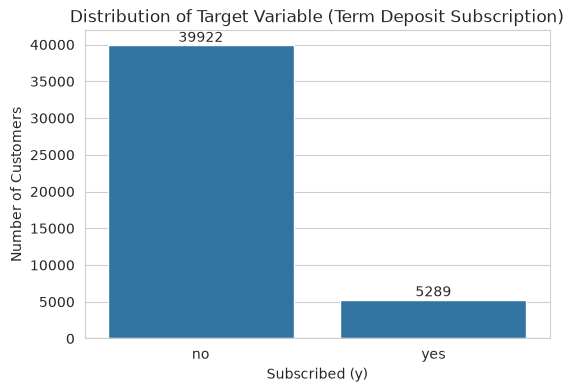

In [5]:
counts = df['y'].value_counts()
pct = df['y'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': counts, 'Percentage': pct.round(2)}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='y', data=df, order=['no', 'yes'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Distribution of Target Variable (Term Deposit Subscription)')
plt.xlabel('Subscribed (y)'); plt.ylabel('Number of Customers')
plt.show()

**Interpretation:** 39,922 customers (88.3%) did not subscribe and only 5,289 (11.7%) subscribed. The data is highly imbalanced, so a model that always says "no" would already get 88% accuracy. This is why accuracy alone cannot be used to pick the best model.

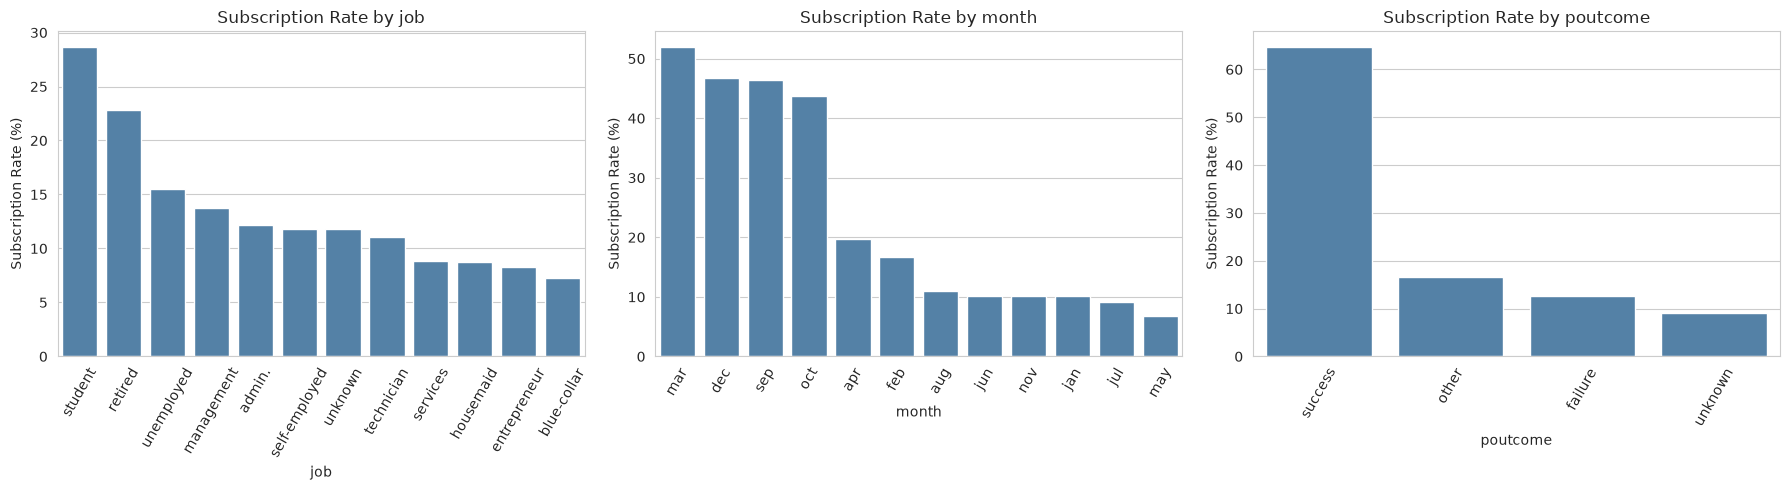

{'student': 28.7, 'retired': 22.8, 'unemployed': 15.5, 'management': 13.8, 'admin.': 12.2, 'unknown': 11.8, 'self-employed': 11.8, 'technician': 11.1, 'services': 8.9, 'housemaid': 8.8, 'entrepreneur': 8.3, 'blue-collar': 7.3}
{'mar': 52.0, 'dec': 46.7, 'sep': 46.5, 'oct': 43.8, 'apr': 19.7, 'feb': 16.6, 'aug': 11.0, 'jun': 10.2, 'nov': 10.2, 'jan': 10.1, 'jul': 9.1, 'may': 6.7}
{'success': 64.7, 'other': 16.7, 'failure': 12.6, 'unknown': 9.2}


In [6]:
df['y_num'] = (df['y'] == 'yes').astype(int)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, col in zip(ax, ['job', 'month', 'poutcome']):
    rate = df.groupby(col)['y_num'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=a, color='steelblue')
    a.set_title(f'Subscription Rate by {col}'); a.set_xlabel(col); a.set_ylabel('Subscription Rate (%)')
    a.tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()
for col in ['job', 'month', 'poutcome']:
    print((df.groupby(col)['y_num'].mean() * 100).round(1).sort_values(ascending=False).to_dict())

**Interpretation:**
- **Job:** students (28.7%) and retired people (22.8%) subscribe far more often than blue-collar workers (7.3%) and entrepreneurs (8.3%).
- **Month:** March (52%), December (46.7%), September (46.5%) and October (43.8%) have very high success rates, even though few calls were made then. May has the most calls but the lowest rate (6.7%).
- **Previous outcome:** customers whose previous campaign was a success subscribe 64.7% of the time, compared with only 9.2% for customers never contacted before.

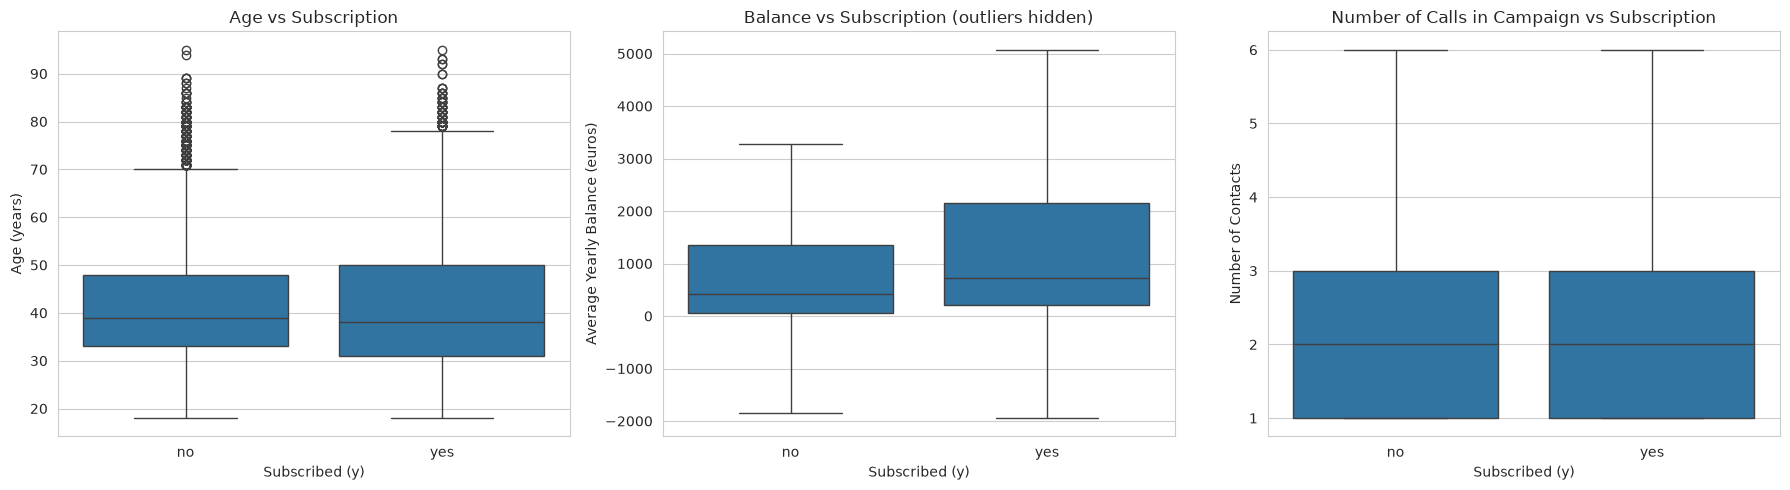

      age  balance  campaign  previous
y                                     
no   39.0    417.0       2.0       0.0
yes  38.0    733.0       2.0       0.0


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x='y', y='age', data=df, ax=ax[0])
ax[0].set_title('Age vs Subscription'); ax[0].set_xlabel('Subscribed (y)'); ax[0].set_ylabel('Age (years)')
sns.boxplot(x='y', y='balance', data=df, ax=ax[1], showfliers=False)
ax[1].set_title('Balance vs Subscription (outliers hidden)'); ax[1].set_xlabel('Subscribed (y)'); ax[1].set_ylabel('Average Yearly Balance (euros)')
sns.boxplot(x='y', y='campaign', data=df, ax=ax[2], showfliers=False)
ax[2].set_title('Number of Calls in Campaign vs Subscription'); ax[2].set_xlabel('Subscribed (y)'); ax[2].set_ylabel('Number of Contacts')
plt.tight_layout(); plt.show()
print(df.groupby('y')[['age', 'balance', 'campaign', 'previous']].median())

**Interpretation:** Median age is almost the same for both groups (38 vs 39), but the age range of subscribers is wider, covering more young and older (retired) customers. Subscribers have a higher median balance (733 vs 417 euros), so customers with more money are more likely to put it in a term deposit. Subscribers were usually contacted fewer times in this campaign; calling the same customer many times does not increase success.

### Three key observations from EDA
1. **A previous success is the strongest sign:** 64.7% of customers with `poutcome = success` subscribed again, about 7 times the overall rate of 11.7%.
2. **Timing matters:** March, September, October and December have success rates above 40%, while the busy month of May has only 6.7%. The bank calls the most when results are poorest.
3. **Customer profile matters:** students and retired customers, and customers with higher balances, are much more likely to subscribe than blue-collar workers.

### Encoding, scaling and train-test split
`duration` is dropped because it is only known after the call ends, so it cannot be used for realistic prediction before contacting a customer.

In [8]:
data = df.drop(columns=['duration', 'y_num'])
X = pd.get_dummies(data.drop(columns='y'), columns=cat_cols, drop_first=True, dtype=int)
y = (data['y'] == 'yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print('Features after encoding:', X.shape[1])
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Subscribed share in train / test:', round(y_train.mean(), 4), round(y_test.mean(), 4))

Features after encoding: 41
Train: (36168, 41)  Test: (9043, 41)
Subscribed share in train / test: 0.117 0.117


Categorical columns are one-hot encoded (giving 41 features) and all features are standardised, which matters for Logistic Regression and especially KNN (distance based). The split is 80:20 and stratified so both sets keep the same ~11.7% subscription rate. The same split is used for all four models.

## Task 3: Classification Model Development
Logistic Regression, Decision Tree and Random Forest use `class_weight='balanced'` so the small 'yes' class is not ignored. The tree depth is limited to reduce overfitting. KNN uses k = 15.

In [9]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced',
                                            random_state=42, n_jobs=-1),
}
results, cms, probs = [], {}, {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    pred = m.predict(X_test_s)
    prob = m.predict_proba(X_test_s)[:, 1]
    cms[name], probs[name] = confusion_matrix(y_test, pred), prob
    results.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred),
                    'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                    'F1-score': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, prob)})
res = pd.DataFrame(results).set_index('Model').round(4)
res

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7557,0.2669,0.6229,0.3737,0.7722
Decision Tree,0.8326,0.3608,0.5586,0.4384,0.7629
KNN,0.8909,0.5962,0.2079,0.3083,0.7441
Random Forest,0.8237,0.3540,0.6144,0.4492,0.7976


## Task 4: Model Performance Comparison and Visualization
### Final performance comparison table

In [10]:
res.sort_values('F1-score', ascending=False)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.8237,0.3540,0.6144,0.4492,0.7976
Decision Tree,0.8326,0.3608,0.5586,0.4384,0.7629
Logistic Regression,0.7557,0.2669,0.6229,0.3737,0.7722
KNN,0.8909,0.5962,0.2079,0.3083,0.7441


**Interpretation:** KNN has the highest accuracy (89.1%) and precision (0.60), but its recall is only 0.21: it finds just 1 in 5 real subscribers. This happens because it mostly predicts "no", the majority class. Random Forest has the best F1-score (0.449) and the best ROC-AUC (0.798), with high recall (0.614). Logistic Regression has the highest recall (0.623) but the lowest precision (0.267), so it produces many false alarms. Decision Tree is in between.

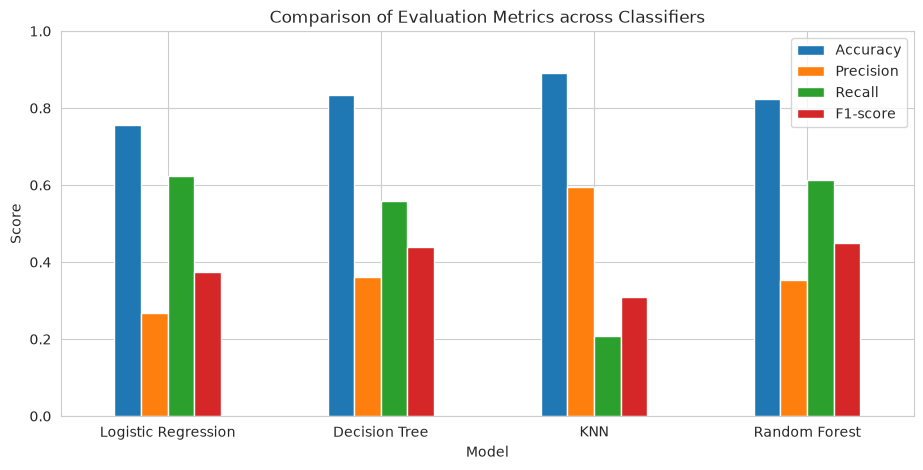

In [11]:
res[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(kind='bar', figsize=(11, 5), rot=0)
plt.title('Comparison of Evaluation Metrics across Classifiers')
plt.xlabel('Model'); plt.ylabel('Score'); plt.ylim(0, 1)
plt.legend(loc='upper right'); plt.show()

**Interpretation:** The chart shows the trade-off between precision and recall. KNN's tall accuracy and precision bars hide a very short recall bar. Random Forest and Decision Tree have the most balanced bars, and Random Forest is slightly ahead on recall and F1-score. All models have fairly low precision because subscribers are rare and are hard to separate without call duration.

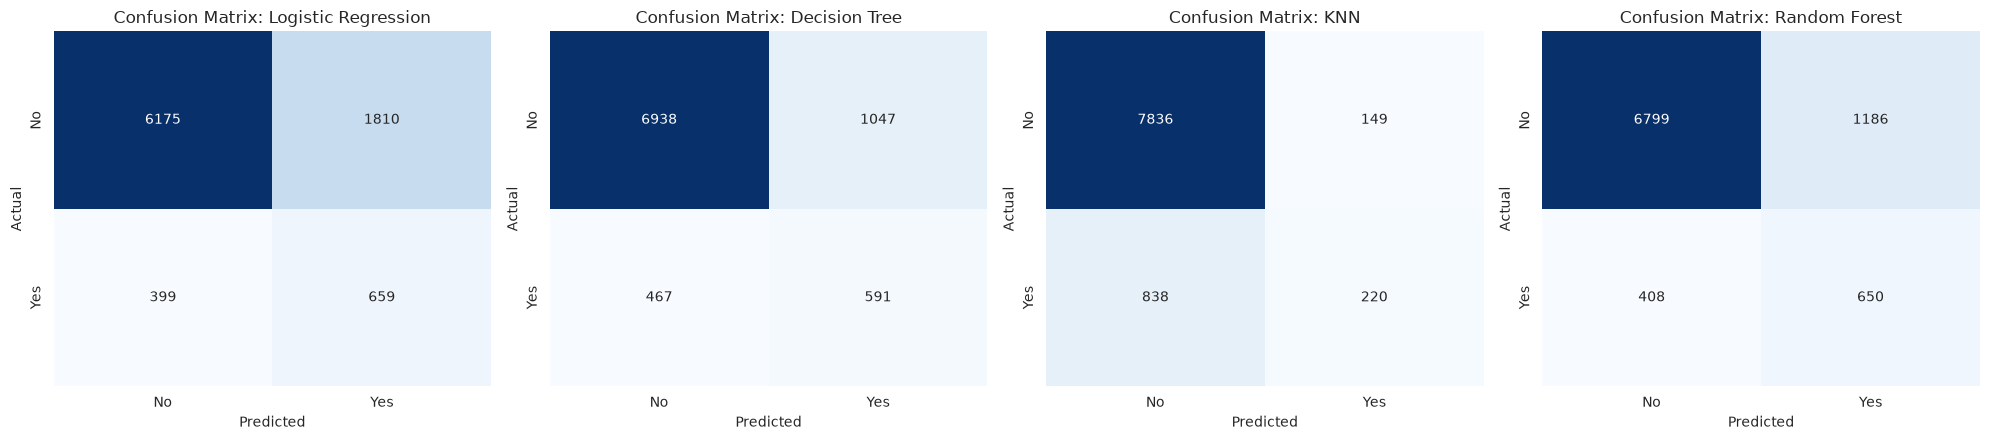

Logistic Regression  TN= 6175 FP= 1810 FN= 399 TP= 659
Decision Tree        TN= 6938 FP= 1047 FN= 467 TP= 591
KNN                  TN= 7836 FP=  149 FN= 838 TP= 220
Random Forest        TN= 6799 FP= 1186 FN= 408 TP= 650


In [12]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, (name, cm) in zip(ax, cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=a, cbar=False,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    a.set_title(f'Confusion Matrix: {name}'); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()
for name, cm in cms.items():
    tn, fp, fn, tp = cm.ravel()
    print(f'{name:20s} TN={tn:5d} FP={fp:5d} FN={fn:4d} TP={tp:4d}')

**Interpretation of errors (9,043 test customers, 1,058 actual subscribers):**
- **Logistic Regression:** catches 659 subscribers but makes 1,810 false positives (wasted calls).
- **Decision Tree:** 591 subscribers caught, 1,047 false positives, 467 missed.
- **KNN:** only 149 false positives, but it misses 838 of 1,058 subscribers (false negatives), losing most of the potential customers.
- **Random Forest:** catches 650 subscribers (almost as many as Logistic Regression) with 624 fewer false positives (1,186).

For the bank, a **false negative** (missing a customer who would have subscribed) loses revenue, while a **false positive** only costs one phone call. So missing subscribers is more expensive, and recall is very important.

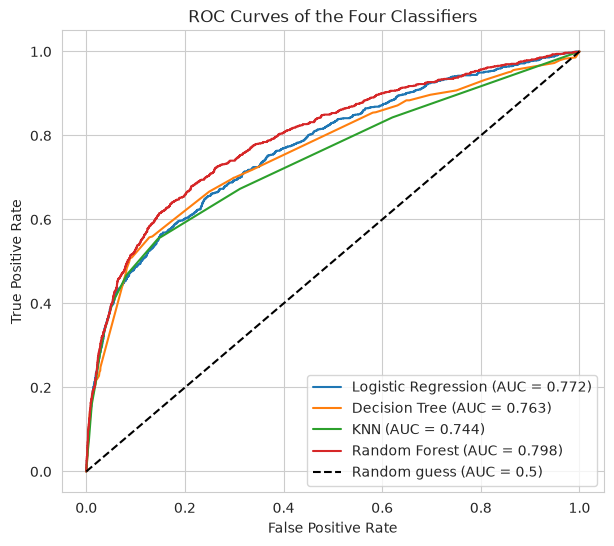

In [13]:
plt.figure(figsize=(7, 6))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {res.loc[name, "ROC-AUC"]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.5)')
plt.title('ROC Curves of the Four Classifiers'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(); plt.show()

**Interpretation:** All four curves are above the random line, so every model has some predictive power even without call duration. Random Forest has the highest curve and AUC (0.798), followed by Logistic Regression (0.772), Decision Tree (0.763) and KNN (0.744). This means Random Forest is best at ranking likely subscribers above non-subscribers over all thresholds.

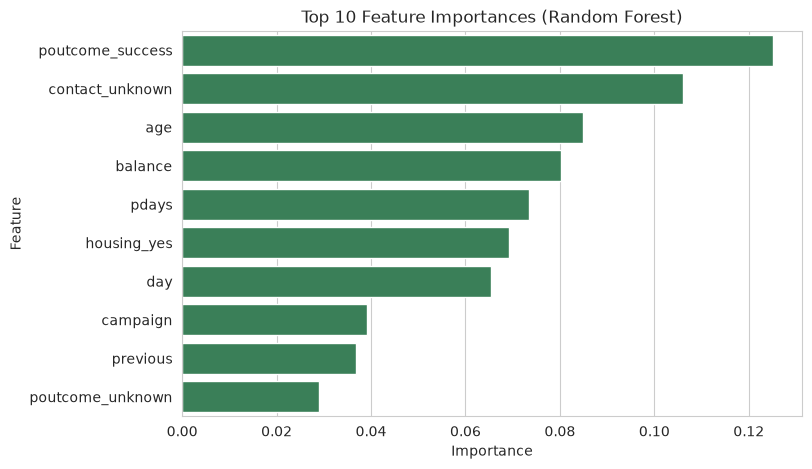

In [14]:
imp = pd.Series(models['Random Forest'].feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color='seagreen')
plt.title('Top 10 Feature Importances (Random Forest)'); plt.xlabel('Importance'); plt.ylabel('Feature')
plt.show()

**Interpretation:** The most important features for Random Forest are previous campaign success (`poutcome_success`), unknown contact type (`contact_unknown`, which has low success), age, balance, days since last contact (`pdays`) and housing loan. This matches the EDA: past behaviour and financial situation are the best signs of a future subscription.

## Task 5: Interpretation and Business Recommendations
### Best model: Random Forest
- It has the **highest F1-score (0.449)** and **highest ROC-AUC (0.798)** of the four models.
- Its **recall (0.614)** is almost equal to the best (Logistic Regression, 0.623), but it has **624 fewer false positives**, so precision is better (0.354 vs 0.267).
- KNN looks best on accuracy (89.1%), but that is misleading on imbalanced data: it misses 79% of subscribers.
- Random Forest also handles non-linear relationships and mixed features well and gives feature importances that the bank can understand.

### Business recommendations
1. **Rank customers by predicted probability and call the top ones first.** Instead of calling everyone, the bank can focus on customers with high scores (e.g. past successes, students, retired, higher balance). This finds about 61% of subscribers while skipping most uninterested customers, saving time and cost.
2. **Change campaign timing and contact strategy.** Run more calls in March, September, October and December, and fewer in May. Limit repeated calls to the same customer, because success does not increase after the first few contacts. Re-contact customers who said yes in earlier campaigns.

### Limitations
1. **Class imbalance and low precision:** only 11.7% are subscribers, and even the best model's precision is 0.35, so about 2 of 3 predicted "yes" customers will still say no. The probability threshold could be tuned to suit the bank's call budget.
2. **Limited features and no tuning:** `duration` was correctly removed, and the remaining data has no information like income or online behaviour. Hyperparameters (k, tree depth, number of trees) were chosen by hand, not by cross-validation, so the results may be slightly better or worse with tuning. The data is also from an older (2008 to 2010) Portuguese campaign and may not generalise to other banks or time periods.

### Conclusion
Four classifiers were compared on the same 80:20 split without the `duration` feature. **Random Forest gave the best balance between finding subscribers and avoiding wasted calls** (F1 = 0.449, ROC-AUC = 0.798) and is recommended for targeting the bank's term deposit campaigns.